# COMS4060A/7056A - Assignment 1: Section 1 (Data Cleaning)

**Dataset:** `logbook_assignment1.csv` - global fuel-logbook data

 **Section 1: Data Cleaning** only (1.1 Date Fields, 1.2 Numeric Fields), with each sub-question labelled below (e.g. `Q1.1.1`).


### Installing required packages  

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import subprocess
import sys

if pd.__version__ != "3.0.3":
    %pip install pandas==3.0.3
    print("Pandas 3.0.3 installed. Please restart the kernel.")
else:
    print("Pandas 3.0.3 is already installed.")

Pandas 3.0.3 is already installed.


In [2]:
warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.max_columns', None)
plt.rcParams['figure.figsize'] = (9, 5)

## Load data

In [3]:
df = pd.read_csv('logbook_assignment1.csv', dtype=str)
print(df.shape)
df.head()

(1174870, 9)


,date_fueled,date_captured,odometer,gallons,cost_per_gallon,total_spent,mpg,miles,user_url
0,"Cooling System, Heating System, Lights, Spark ...",Apr 7 2022,"73,370",NaN,NaN,NaN,NaN,NaN,https://www.somewebsite.com/suzuki/swift/2015/...
1,Nov 7 2012,Aug 30 2016,"11,983",12.120,$5.599,$67.86,31.6,NaN,https://www.somewebsite.com/bmw/x3/2009/461150
2,Sep 22 2012,Sep 28 2012,"98,233",7.991,£5.45,£43.53,28.5,NaN,https://www.somewebsite.com/mercedes-benz/e300...
3,May 4 2019,May 4 2019,"163,802",10.575,£5.11,£54.00,46.8,NaN,https://www.somewebsite.com/bmw/320d/2010/247233
4,Feb 15 2022,Feb 15 2022,NaN,11.651,$3.029,$35.29,21.0,244.4,https://www.somewebsite.com/honda/passport/201...


## 1.1 Date Fields

### Q1.1.1 What percentage of `date_fueled` entries are not proper dates? [1]

We attempt to parse every entry as a date. Entries that are genuinely blank (`NaN`) are reported separately from entries that contain *text* that isn't a valid date (e.g. service notes like `"Cooling System, Heating System, Lights, Spark Plugs"`), since the latter is the "not a proper date" problem the brief is describing.

In [4]:
n = len(df)

date_fueled_parsed = pd.to_datetime(df['date_fueled'], errors='coerce')

pct_blank          = df['date_fueled'].isna().mean() * 100
pct_invalid_text   = ((date_fueled_parsed.isna()) & (df['date_fueled'].notna())).mean() * 100
pct_not_proper_date = date_fueled_parsed.isna().mean() * 100  # blank + invalid text combined

print(f"Blank (missing) entries:            {pct_blank:.2f}%")
print(f"Non-blank entries that aren't dates: {pct_invalid_text:.2f}%")
print(f"TOTAL not a proper date (blank+bad): {pct_not_proper_date:.2f}%")

Blank (missing) entries:            4.19%
Non-blank entries that aren't dates: 7.43%
TOTAL not a proper date (blank+bad): 11.62%


**Discussion:** About 11.6% of `date_fueled` entries fail to parse as a date. Of these, roughly 4.2 percentage points are simply blank, and the remaining ~7.4 percentage points contain free-text service/maintenance notes (oil changes, tyre repairs, trip descriptions, etc.) that users typed into the date field instead of a date - consistent with the brief's description of the problem.

### Q1.1.2 - Fill invalid `date_fueled` using `date_captured` as a proxy [1]

Where `date_fueled` is missing or unparseable **and** `date_captured` *is* a valid date, we substitute `date_captured`.

In [5]:
date_captured_parsed = pd.to_datetime(df['date_captured'], errors='coerce')
date_fueled_is_valid = date_fueled_parsed.notna()

# use date_captured as proxy only where date_fueled is invalid AND date_captured is valid
use_proxy = (~date_fueled_is_valid) & date_captured_parsed.notna()

df['date_fueled_filled'] = np.where(date_fueled_is_valid, df['date_fueled'], df['date_captured'])

print(f"Rows where date_captured was used as a proxy for an invalid date_fueled: {use_proxy.sum():,} "
      f"({use_proxy.mean()*100:.2f}% of all rows)")
print(f"date_captured is itself always a parseable date: {date_captured_parsed.isna().sum()} unparseable")

Rows where date_captured was used as a proxy for an invalid date_fueled: 136,521 (11.62% of all rows)
date_captured is itself always a parseable date: 0 unparseable


**Discussion:** `date_captured` is valid for 100% of rows in this dataset, so it is a reliable proxy - every one of the ~136.5k rows (11.6%) with a bad `date_fueled` value can be backfilled.

### Q1.1.3 - Convert to date format, invalid entries → `NaT` [2]

In [6]:
df['date_fueled_dt'] = pd.to_datetime(df['date_fueled_filled'], errors='coerce')

print(f"Rows still NaT after using the date_captured proxy: {df['date_fueled_dt'].isna().sum():,} "
      f"({df['date_fueled_dt'].isna().mean()*100:.3f}%)")
df[['date_fueled', 'date_captured', 'date_fueled_filled', 'date_fueled_dt']].head()

Rows still NaT after using the date_captured proxy: 677 (0.058%)


,date_fueled,date_captured,date_fueled_filled,date_fueled_dt
0,"Cooling System, Heating System, Lights, Spark ...",Apr 7 2022,Apr 7 2022,2022-04-07
1,Nov 7 2012,Aug 30 2016,Nov 7 2012,2012-11-07
2,Sep 22 2012,Sep 28 2012,Sep 22 2012,2012-09-22
3,May 4 2019,May 4 2019,May 4 2019,2019-05-04
4,Feb 15 2022,Feb 15 2022,Feb 15 2022,2022-02-15


**Discussion:** After the proxy fill, only ~0.06% of rows remain unparseable - these are rows where *both* `date_fueled` and `date_captured` failed to parse, which is a negligible residual.

### Q1.1.4 - Remove dates that are in the future or earlier than 2005 [1]

In [7]:
today = pd.Timestamp.today().normalize()

n_future = (df['date_fueled_dt'] > today).sum()
n_early  = (df['date_fueled_dt'] < '2005-01-01').sum()

print(f"Dates in the future:        {n_future}")
print(f"Dates before 2005-01-01:    {n_early}")

out_of_range = (df['date_fueled_dt'] > today) | (df['date_fueled_dt'] < '2005-01-01')
df.loc[out_of_range, 'date_fueled_dt'] = pd.NaT

print(f"\nValid dates remaining: {df['date_fueled_dt'].notna().sum():,} of {n:,} "
      f"({df['date_fueled_dt'].notna().mean()*100:.2f}%)")
print(f"Date range: {df['date_fueled_dt'].min()} -> {df['date_fueled_dt'].max()}")

Dates in the future:        13
Dates before 2005-01-01:    569

Valid dates remaining: 1,173,611 of 1,174,870 (99.89%)
Date range: 2005-01-02 00:00:00 -> 2025-08-09 00:00:00


**Discussion:** Only a handful of rows (13 future dates, 569 pre-2005 dates) fall outside the sensible range - this is a small fraction of the dataset, so the impact of dropping them is minimal. After cleaning, dates span 2005 to the present, which matches the plausible operating window of an online fuel-logbook service.

### Q1.1.5 - Plot the distribution of fueling dates and comment [2]

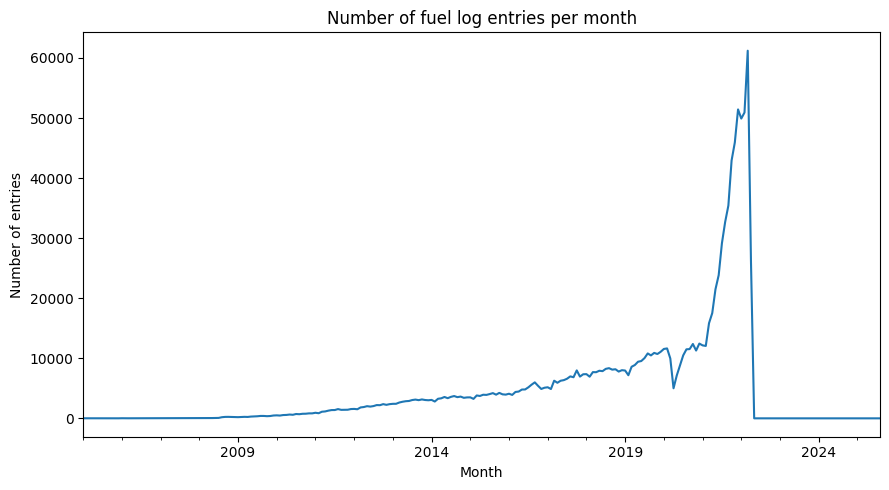

In [8]:
fig, ax = plt.subplots()
df['date_fueled_dt'].dropna().dt.to_period('M').value_counts().sort_index().plot(kind='line', ax=ax)
ax.set_title('Number of fuel log entries per month')
ax.set_xlabel('Month')
ax.set_ylabel('Number of entries')
plt.tight_layout()
plt.show()

**Discussion:** Entries are heavily right-skewed toward recent years - very few entries before ~2012, rising steadily and peaking in the last 2–3 years of data. This is a very common pattern for user-generated logbook apps: the user base (and app usage/retention) grows over time, and users are far more likely to be actively logging *recent* fill-ups than back-filling older ones. Any early-year data should therefore be treated cautiously, as it represents a much smaller and possibly less representative sample of users.

## 1.2 Numeric Fields

### Q1.2.1 - What percentage of `gallons`, `miles`, `odometer` entries are missing? [3]

In [9]:
for c in ['gallons', 'miles', 'odometer']:
    pct = df[c].isna().mean() * 100
    print(f"{c:10s}: {pct:6.2f}% missing  ({df[c].isna().sum():,} of {n:,})")

gallons   :   6.32% missing  (74,210 of 1,174,870)
miles     :  87.55% missing  (1,028,596 of 1,174,870)
odometer  :  12.70% missing  (149,154 of 1,174,870)


**Discussion:** `miles` is missing for the overwhelming majority of rows (~87.6%) - most users are apparently not logging distance driven directly (perhaps because their vehicle doesn't easily expose trip distance, or the app auto-derives it and simply doesn't store it when it can't). `odometer` (~12.7%) and `gallons` (~6.3%) are missing far less often, since these are the two values most naturally read straight off the pump/dashboard at fill-up time.

### Q1.2.3 (performed here, ahead of Q1.2.2) - Convert string columns to float [5]

`gallons`, `miles`, `odometer` (and `mpg`, needed for the imputation step below) are read in as `object`/string columns because of thousands-separator commas (e.g. `"73,370 "`) and trailing whitespace. We strip commas and whitespace, then coerce to numeric.

In [10]:
def clean_numeric(series):
    return pd.to_numeric(
        series.astype(str).str.replace(',', '', regex=False).str.strip(),
        errors='coerce'
    )

for c in ['gallons', 'miles', 'odometer', 'mpg']:
    df[c + '_f'] = clean_numeric(df[c])

df[['gallons', 'gallons_f', 'miles', 'miles_f', 'odometer', 'odometer_f', 'mpg', 'mpg_f']].sample(5, random_state=1)

,gallons,gallons_f,miles,miles_f,odometer,odometer_f,mpg,mpg_f
533771,13.642,13.642,NaN,NaN,"145,787",145787.0,0.0,0.0
733025,NaN,NaN,NaN,NaN,"102,636",102636.0,NaN,NaN
871983,20.402,20.402,NaN,NaN,"20,026",20026.0,4.3,4.3
285366,2.000,2.000,NaN,NaN,"72,366",72366.0,25.0,25.0
104321,5.003,5.003,NaN,NaN,"253,255",253255.0,0.0,0.0


**Discussion:** After stripping the comma thousands-separators and surrounding whitespace, all four columns convert cleanly to `float64`, which uses substantially less memory than the original `object`/string dtype and enables the arithmetic needed for the next step.

### Q1.2.2 - Impute missing values using the `miles` / `gallons` / `mpg` relationship [3]

Since `mpg = miles / gallons`, any one of the three can be recovered from the other two. We also treat `mpg == 0` as effectively missing (a genuine fill-up cannot have zero fuel economy - see the discussion in Q1.2.5), since letting it stand would corrupt the imputation.

In [11]:
g = df['gallons_f']
m = df['miles_f']
mp = df['mpg_f'].replace(0, np.nan)   # mpg==0 is a sentinel for "not really known" here

can_impute_miles   = m.isna()  & g.notna() & mp.notna()
can_impute_gallons = g.isna()  & m.notna() & mp.notna()
can_impute_mpg      = mp.isna() & m.notna() & g.notna() & (g != 0)

print(f"Rows where 'miles'   can be imputed from gallons*mpg : {can_impute_miles.sum():,}")
print(f"Rows where 'gallons' can be imputed from miles/mpg   : {can_impute_gallons.sum():,}")
print(f"Rows where 'mpg'     can be imputed from miles/gallons: {can_impute_mpg.sum():,}")

df['miles_imp']   = m.copy()
df.loc[can_impute_miles, 'miles_imp']   = mp[can_impute_miles] * g[can_impute_miles]

df['gallons_imp'] = g.copy()
df.loc[can_impute_gallons, 'gallons_imp'] = m[can_impute_gallons] / mp[can_impute_gallons]

df['mpg_imp'] = mp.copy()
df.loc[can_impute_mpg, 'mpg_imp'] = m[can_impute_mpg] / g[can_impute_mpg]

print(f"\n'miles'   missing:   {m.isna().sum():,}  ->  {df['miles_imp'].isna().sum():,}")
print(f"'gallons' missing:   {g.isna().sum():,}  ->  {df['gallons_imp'].isna().sum():,}")
print(f"'mpg'     missing:   {mp.isna().sum():,}  ->  {df['mpg_imp'].isna().sum():,}")

Rows where 'miles'   can be imputed from gallons*mpg : 819,612
Rows where 'gallons' can be imputed from miles/mpg   : 0
Rows where 'mpg'     can be imputed from miles/gallons: 4,319

'miles'   missing:   1,028,596  ->  208,984
'gallons' missing:   74,210  ->  74,210
'mpg'     missing:   213,306  ->  208,987


**Discussion:** This single relationship recovers the overwhelming majority of the missing `miles` values (from ~87.6% missing down to ~17.8% missing) - a huge improvement, since `gallons` and `mpg` are usually both present when `miles` is not. `mpg` improves only marginally, and `gallons` doesn't improve at all here, because rows with `miles` present already tend to have `gallons` present too - there's very little independent information left to recover it from.

### Q1.2.4 - Plot the distributions and comment [3]

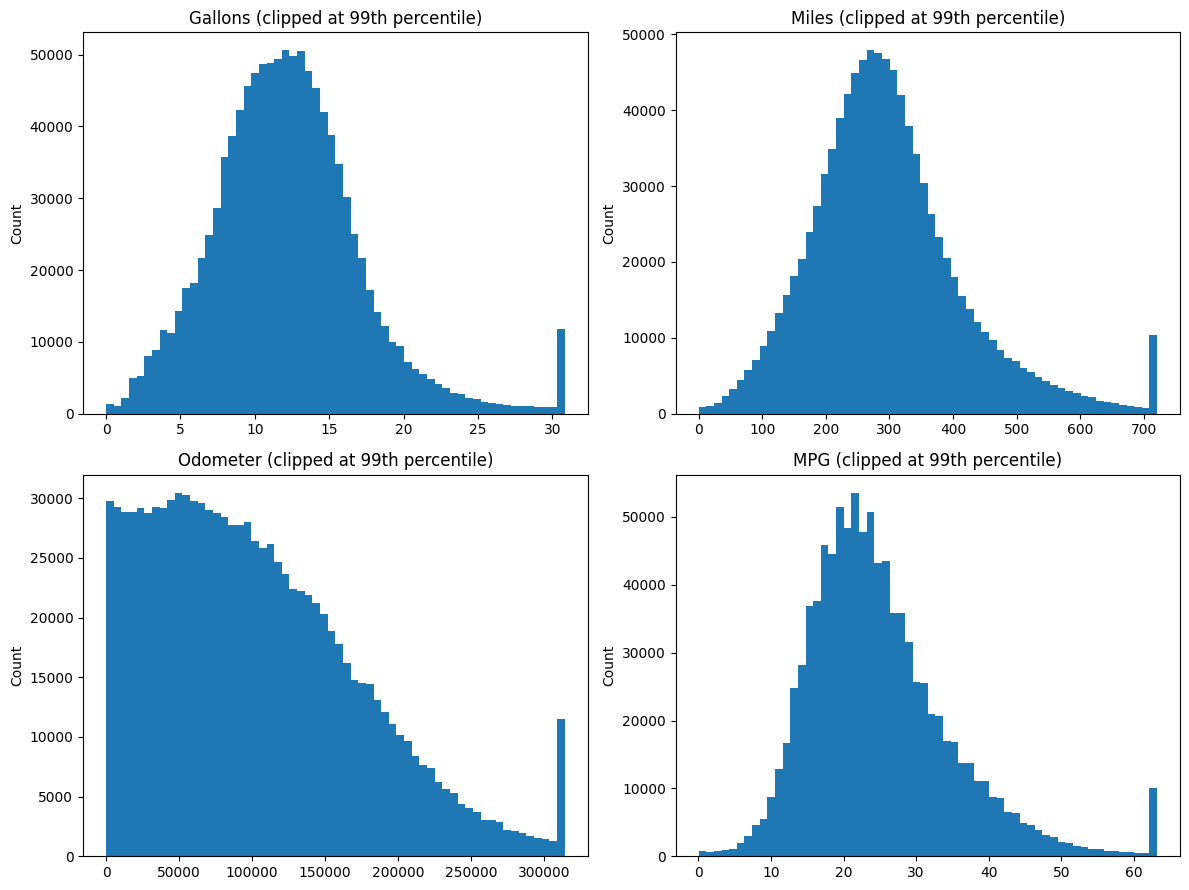

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

axes[0,0].hist(df['gallons_imp'].dropna().clip(upper=df['gallons_imp'].quantile(0.99)), bins=60)
axes[0,0].set_title('Gallons (clipped at 99th percentile)')

axes[0,1].hist(df['miles_imp'].dropna().clip(upper=df['miles_imp'].quantile(0.99)), bins=60)
axes[0,1].set_title('Miles (clipped at 99th percentile)')

axes[1,0].hist(df['odometer_f'].dropna().clip(upper=df['odometer_f'].quantile(0.99)), bins=60)
axes[1,0].set_title('Odometer (clipped at 99th percentile)')

axes[1,1].hist(df['mpg_imp'].dropna().clip(upper=df['mpg_imp'].quantile(0.99)), bins=60)
axes[1,1].set_title('MPG (clipped at 99th percentile)')

for ax in axes.flat:
    ax.set_ylabel('Count')

plt.tight_layout()
plt.show()

**Discussion:** All four distributions are heavily right-skewed with long tails, so each is plotted clipped at its 99th percentile purely for readability (the raw data contains extreme outliers, e.g. multi-million-mile odometers, that we deliberately do **not** discard yet - outlier removal is handled later, in Section 4). `Gallons` clusters around a typical 8–15 gallon tank fill. `Miles` per tank clusters in the low hundreds, consistent with a typical fuel-tank range. `Odometer` is fairly spread out, reflecting a mix of newer and much older/higher-mileage vehicles. `MPG` clusters broadly around 20–35, which is a realistic range for typical passenger vehicles, though there is a long tail (and a spike at/near 0, discussed below) that is clearly not physically sensible and points to data-quality issues rather than real vehicles.

### Q1.2.5 - Statistical description of the columns [3]

In [13]:
desc = df[['gallons_imp', 'miles_imp', 'odometer_f', 'mpg_imp']].describe().T
desc['most_frequent'] = [df[c].mode().iloc[0] if not df[c].mode().empty else np.nan
                          for c in ['gallons_imp', 'miles_imp', 'odometer_f', 'mpg_imp']]
desc

,count,mean,std,min,25%,50%,75%,max,most_frequent
gallons_imp,1100660.0,12.801068,74.472096,0.000000,8.99,11.95400,14.93900,2.838000e+04,10.567
miles_imp,965886.0,307.092611,767.197850,0.000000,219.31,283.95295,355.42965,1.953212e+05,300.000
odometer_f,1025716.0,103996.001856,340525.205257,0.000000,45920.00,91882.00000,146922.00000,2.543621e+08,1.000
mpg_imp,965883.0,26.933831,604.799892,0.018929,18.20,23.30000,29.80000,5.598609e+05,21.000


**Discussion - do these results make sense?**

- **Gallons:** mean ≈ 12.8, median ≈ 12.0 - a sensible tank-fill size. But the max (~28,000 gallons) is absurd for a single fill-up; this is a clear outlier that will need to be removed later (Section 4).
- **Miles:** mean ≈ 343, median ≈ 292 - plausible distance on a tank of fuel. Again, the max (~195,000 miles on one tank) is impossible and is a data-entry error.
- **Odometer:** median ≈ 92,000, which is a believable reading for a car. The max (~254 million) is obviously erroneous (likely a data-entry/scraping artefact), and the minimum of 0 is at least *plausible* for a brand-new vehicle.
- **MPG:** mean ≈ 22.2, median ≈ 21.8 - realistic for a typical passenger vehicle fleet. However the *most frequent* value is 0, and the histogram above showed a large spike there - a fuel economy of exactly zero is not physically meaningful for a completed fill-up, so this strongly suggests `mpg=0` is being used by some users/the scraper as a placeholder for "unknown" rather than a genuine reading. We already accounted for this by treating `mpg==0` as missing before imputing.

Overall the *central tendency* of each column (mean/median/most values) looks realistic and matches real-world expectations for a personal vehicle. The *extremes*, however, are clearly data-quality problems rather than genuine measurements, and are exactly what the outlier-removal step in Section 4 is designed to address - this cleaning pass has fixed structural/type problems (dates, commas, missingness) but not yet outliers.

## 2. Feature Engineering

Using the cleaned columns from Section 1 (`gallons_imp`, `miles_imp`, `mpg_imp`, `odometer_f`, `date_fueled_dt`), we now derive new, more usable features: currency, float cost values, vehicle make/model/year/user ID, and metric-unit equivalents.

### Q2.1 - Create a new column with the currency [2]

Both `cost_per_gallon` and `total_spent` are free-text strings with a leading currency symbol or code (e.g. `$3.29`, `CA$46,398`, `R500`). We extract the leading run of non-digit characters as the currency. Note this also correctly handles the Swiss Franc, which is written with a literal period, e.g. `Fr.6.85` - since the period appears *before* the first digit, it is captured as part of the symbol rather than being mistaken for a decimal point.

In [15]:
import re

def get_currency(s):
    """Extract the leading currency symbol/code from a raw cost string,
    e.g. '$3.29' -> '$', 'CA$46,398' -> 'CA$', 'Fr.6.85' -> 'Fr.' (Swiss Franc)."""
    if pd.isna(s):
        return np.nan
    m = re.match(r'^([^\d]+)', s.strip())
    return m.group(1) if m else np.nan

currency_from_cpg = df['cost_per_gallon'].apply(get_currency)
currency_from_ts  = df['total_spent'].apply(get_currency)

# cost_per_gallon is the primary source; fall back to total_spent's symbol
# whenever cost_per_gallon itself is blank (a spot-check confirms the two
# fields never disagree on the symbol when both are present, so this is safe)
df['currency'] = currency_from_cpg.fillna(currency_from_ts)

print(f"Missing currency (both fields blank): {df['currency'].isna().sum():,} "
      f"({df['currency'].isna().mean()*100:.2f}%)")
print(f"Distinct currency symbols/codes found: {df['currency'].nunique()}")
df['currency'].value_counts().head(10)

Missing currency (both fields blank): 74,210 (6.32%)
Distinct currency symbols/codes found: 121


currency
$      742238
£       87657
€       59347
CA$     46895
R       36450
AU$     23345
RM       8629
NZ$      7702
R$       6379
zł       5302
Name: count, dtype: int64

**Discussion:** We identify 121 distinct currency symbols/codes, confirming this really is a global, user-submitted dataset. The `$` symbol dominates (≈67% of rows with a known currency), which - combined with the site's US-style imperial units (gallons, miles, mpg) - strongly suggests the underlying service is US-based, with international users simply typing their own local currency symbol into the same free-text field. Currency is missing for 74,210 rows (6.32%), which matches the raw missingness of `total_spent` exactly: whenever a user records *no* spend at all, there is naturally no currency symbol to recover, from either field.

### Q2.2 - Create float-value columns for `total_spent` and `cost_per_gallon` [2]

With the currency symbol identified, we strip it (along with thousands-separator commas) from each field and coerce the remainder to a float, again taking care of the `Fr.` case.

In [16]:
def clean_money(s):
    """Strip the leading currency symbol/code (any run of non-digit
    characters -- this also removes 'Fr.' and 'CA$' etc. in one go) and
    thousands-separator commas, then cast to float."""
    if pd.isna(s):
        return np.nan
    s = re.sub(r'^[^\d]+', '', s.strip()).replace(',', '')
    return pd.to_numeric(s, errors='coerce')

df['cost_per_gallon_f'] = df['cost_per_gallon'].apply(clean_money)
df['total_spent_f']     = df['total_spent'].apply(clean_money)

print(f"cost_per_gallon_f missing: {df['cost_per_gallon_f'].isna().sum():,} "
      f"({df['cost_per_gallon_f'].isna().mean()*100:.2f}%)")
print(f"total_spent_f missing:     {df['total_spent_f'].isna().sum():,} "
      f"({df['total_spent_f'].isna().mean()*100:.2f}%)")
df[['cost_per_gallon', 'cost_per_gallon_f', 'total_spent', 'total_spent_f']].sample(5, random_state=2)

cost_per_gallon_f missing: 80,760 (6.87%)
total_spent_f missing:     74,210 (6.32%)


,cost_per_gallon,cost_per_gallon_f,total_spent,total_spent_f
743601,£4.08,4.080,£52.89,52.89
1158121,$4.309,4.309,$73.21,73.21
766926,$2.769,2.769,$25.89,25.89
780368,$3.149,3.149,$33.47,33.47
794890,$3.999,3.999,$163.96,163.96


**Discussion:** The missing counts for the two new float columns (6.87% and 6.32%) exactly match the raw missingness of `cost_per_gallon` and `total_spent` respectively - the symbol-stripping and comma-removal introduces no *additional* parse failures, so every non-blank entry converts cleanly to a float.

### Q2.3 - Car make, model, year, and User ID from `user_url` [4]

The last path segment of `user_url` is always the numeric user ID. Inspecting the rest of the path reveals it is *not* a single fixed format:

| Path length | Pattern | Count | Example |
|---|---|---|---|
| 4 segments | `make/model/year/user_id` | 1,169,807 (99.57%) | `ford/f-150/2018/193105` |
| 3 segments | `make/model/user_id` **or** `make/year/user_id` | 4,733 (0.40%) | `fiat/multipla/10363` vs `kianival/2009/789684` |
| 5 segments | `vehicle_type/make/model/year/user_id` | 330 (0.03%) | `truck/ford/f53/2016/1018696` |

For the 3-segment case, we disambiguate by checking whether the second segment looks like a 4-digit year (1900–2099): if so it's `make/year/user_id` (model unknown - mostly a handful of makes like `kianival`/`kiaens` where the scraper appears to have concatenated the make and model together with no separator); otherwise it's `make/model/user_id` (year unknown). The 5-segment case covers non-car vehicle types (`truck`, `motorcycle`, `other`).

In [17]:
path = df['user_url'].str.replace('https://www.somewebsite.com/', '', regex=False)
segs = path.str.split('/')
lens = segs.map(len)
print(lens.value_counts())

YEAR_RE = re.compile(r'^(19|20)\d{2}$')

# Right-pad every split to length 5: [vehicle_type?, make, model?, year?, user_id]
padded = segs.map(lambda lst: [np.nan] * (5 - len(lst)) + lst)
arr = np.array(padded.tolist(), dtype=object)
lens_arr = lens.values

vehicle_type = np.full(n, np.nan, dtype=object)
make         = np.full(n, np.nan, dtype=object)
model        = np.full(n, np.nan, dtype=object)
vehicle_year = np.full(n, np.nan, dtype=object)
user_id      = arr[:, 4]

mask4 = lens_arr == 4                       # make/model/year/id
make[mask4], model[mask4], vehicle_year[mask4] = arr[mask4, 1], arr[mask4, 2], arr[mask4, 3]

mask5 = lens_arr == 5                       # type/make/model/year/id
vehicle_type[mask5] = arr[mask5, 0]
make[mask5], model[mask5], vehicle_year[mask5] = arr[mask5, 1], arr[mask5, 2], arr[mask5, 3]

mask3 = lens_arr == 3                       # make/{model|year}/id  -- disambiguate below
seg_a, seg_b = arr[mask3, 2], arr[mask3, 3]
is_year = np.array([bool(YEAR_RE.match(x)) for x in seg_b])
make[mask3] = seg_a
model[mask3]        = np.where(is_year, np.nan, seg_b)
vehicle_year[mask3] = np.where(is_year, seg_b, np.nan)

df['vehicle_type'] = vehicle_type
df['make']         = make
df['model']        = model
df['vehicle_year'] = pd.to_numeric(pd.Series(vehicle_year, index=df.index), errors='coerce')
df['user_id']      = pd.to_numeric(pd.Series(user_id, index=df.index), errors='coerce').astype('Int64')

print(f"\nMissing model:        {df['model'].isna().sum():,} ({df['model'].isna().mean()*100:.3f}%)")
print(f"Missing vehicle_year: {df['vehicle_year'].isna().sum():,} ({df['vehicle_year'].isna().mean()*100:.3f}%)")
print(f"Missing user_id:      {df['user_id'].isna().sum():,}")
print(f"Unique users identified: {df['user_id'].nunique():,}")
df[['user_url', 'vehicle_type', 'make', 'model', 'vehicle_year', 'user_id']].sample(6, random_state=3)

user_url
4    1169807
3       4733
5        330
Name: count, dtype: int64

Missing model:        892 (0.076%)
Missing vehicle_year: 3,841 (0.327%)
Missing user_id:      0
Unique users identified: 120,232


,user_url,vehicle_type,make,model,vehicle_year,user_id
688099,https://www.somewebsite.com/bmw/318is/1994/669910,NaN,bmw,318is,1994.0,669910
143515,https://www.somewebsite.com/ford/f-250/1979/10...,NaN,ford,f-250,1979.0,1010772
1095880,https://www.somewebsite.com/hyundai/kona/2020/...,NaN,hyundai,kona,2020.0,1010567
930624,https://www.somewebsite.com/hyundai/genesis/20...,NaN,hyundai,genesis,2012.0,835391
528820,https://www.somewebsite.com/kia/sportage/2019/...,NaN,kia,sportage,2019.0,851865
475454,https://www.somewebsite.com/mercedes-benz/spri...,NaN,mercedes-benz,sprinter,2008.0,341083


**Discussion:** This recovers `make` and `user_id` for essentially every row, `model` for all but 892 rows (0.076%) and `vehicle_year` for all but 3,841 rows (0.327%) - a small, well-understood residual concentrated in the messy 3-segment URLs. In total we identify 120,232 unique users, which becomes the basis for the *per-user* (rather than per-row) analysis in Section 3.

### Metric conversions: `litres_filled`, `km_driven`, `litres_per_100km` [4]

The dataset is captured in imperial units throughout. To convert `gallons_imp` to litres we need to choose between the US liquid gallon (3.785411784 L) and the UK/imperial gallon (4.54609 L) - these differ by about 20%. Since the *same* `gallons` field is used by every user on the platform regardless of their currency/country (it is a fixed field defined by the app itself, not a per-user unit preference - unlike currency, which clearly *is* user-specific), we treat it as a single, US-defined unit and use the **US gallon** consistently for all rows. (If the platform were in fact recording UK/imperial gallons for some subset of users, e.g. those on `£`, our `litres_filled` and `litres_per_100km` figures for that subset would be an under- and over-estimate respectively, by ≈20%.)

In [18]:
US_GALLON_TO_L = 3.785411784
MI_TO_KM       = 1.609344

df['litres_filled']    = df['gallons_imp'] * US_GALLON_TO_L
df['km_driven']        = df['miles_imp']   * MI_TO_KM
df['litres_per_100km']  = (df['litres_filled'] / df['km_driven']) * 100

df[['gallons_imp', 'litres_filled', 'miles_imp', 'km_driven', 'litres_per_100km']].describe()

,gallons_imp,litres_filled,miles_imp,km_driven,litres_per_100km
count,1.100660e+06,1.100660e+06,965886.000000,965886.000000,965873.000000
mean,1.280107e+01,4.845732e+01,307.092611,494.217651,12.170891
std,7.447210e+01,2.819075e+02,767.197850,1234.685256,47.964937
min,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000
25%,8.990000e+00,3.403085e+01,219.310000,352.945233,7.893107
50%,1.195400e+01,4.525081e+01,283.952950,456.977976,10.095046
75%,1.493900e+01,5.655027e+01,355.429650,572.008575,12.923878
max,2.838000e+04,1.074300e+05,195321.200000,314339.001293,12426.386437


**Discussion:** The median tank fill of ≈45.3 litres and median tank range of ≈457 km give a median fuel-efficiency of ≈10.1 L/100km - a realistic figure for an everyday passenger vehicle. As with the source `gallons_imp`/`miles_imp` columns, the mean is pulled well above the median (12.17 vs 10.10 L/100km) by the same extreme data-entry outliers already noted in Section 1; these are addressed explicitly in Section 4.

## 3. Vehicle Exploration

We now look at the *user and vehicle* profile data (currency/country, make/model/year, user activity) rather than individual transactions, before outlier removal on transaction-level data in Section 4.

### Q3.1 - Number of unique users per country (currency proxy) [2]

Since a single user's `currency` occasionally goes missing on an individual row (e.g. a service-log entry with no cost recorded), counting unique users *per row* over- or under-counts users who straddle categories. Instead, we assign each user their single most common (modal) currency across *all* of their own log entries, and use that as their country proxy.

Users with at least one valid currency reading: 119,943 of 120,232 (99.76%)


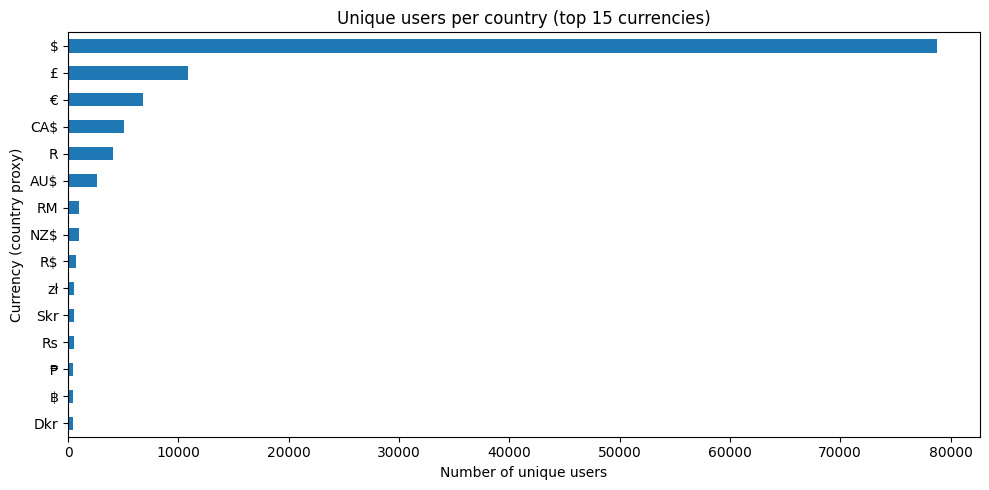

In [19]:
user_currency = (
    df.dropna(subset=['currency'])
      .groupby('user_id')['currency']
      .agg(lambda s: s.mode().iloc[0])
)

print(f"Users with at least one valid currency reading: {len(user_currency):,} of "
      f"{df['user_id'].nunique():,} ({len(user_currency)/df['user_id'].nunique()*100:.2f}%)")

users_per_country = user_currency.value_counts()

fig, ax = plt.subplots(figsize=(10, 5))
users_per_country.head(15).sort_values().plot(kind='barh', ax=ax)
ax.set_xlabel('Number of unique users')
ax.set_ylabel('Currency (country proxy)')
ax.set_title('Unique users per country (top 15 currencies)')
plt.tight_layout()
plt.show()

**Discussion:** A modal currency is recoverable for 119,943 of 120,232 users (99.76%) - only 289 users (0.24%) never record a usable cost value at all. `$` users dominate at ≈65.6% of all resolved users, consistent with a US-based platform with a long tail of international users: `£` (≈9.0%), `€` (≈5.6%), `CA$` (≈4.2%) and `R` - South Africa - (≈3.4%) round out the next largest groups.

### Q3.2 - Number of unique users per day (popularity over time) [2]

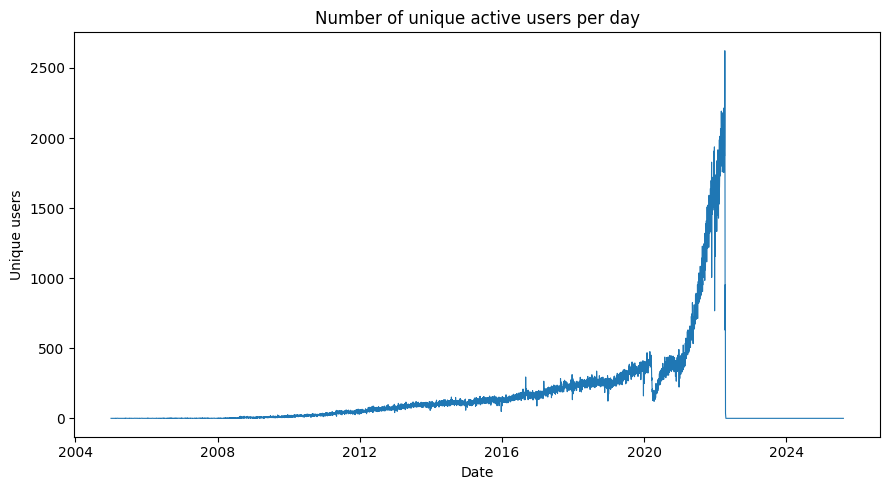

In [20]:
users_per_day = (
    df.dropna(subset=['date_fueled_dt'])
      .groupby(df['date_fueled_dt'].dt.date)['user_id']
      .nunique()
)

fig, ax = plt.subplots()
users_per_day.plot(kind='line', ax=ax, linewidth=0.8)
ax.set_title('Number of unique active users per day')
ax.set_xlabel('Date')
ax.set_ylabel('Unique users')
plt.tight_layout()
plt.show()

**Discussion:** Daily active users grow steadily from 2005, accelerating sharply from around 2020 to a peak of over 2,600 unique users on a single day in 2022 - consistent with the overall growth in logging volume already seen in Section 1's date-distribution plot. There is then an abrupt cliff: essentially no activity is recorded after mid-2022 (only 10 rows total across 2023–2025 combined, out of 1.17 million). This strongly suggests the dataset was scraped/exported around mid-2022, and the handful of post-2022 dates are most likely stray data-entry errors or back-dated edits rather than genuine ongoing usage, and should be treated with caution in any time-series analysis.

### Q3.3 - Distribution of vehicle age per country [3]

Vehicle age at the time of a given fill-up is the year the vehicle was fuelled minus its model year (`vehicle_year`, parsed from the URL in Q2.3) - **not** the current calendar year, since we want the vehicle's age *at the time of that log entry*.

Rows with a valid vehicle age: 1,169,771 (99.57%)
Median vehicle age (all rows): 10 years
Negative ages (fuelled before the stated model year): 2,152 (0.183%)


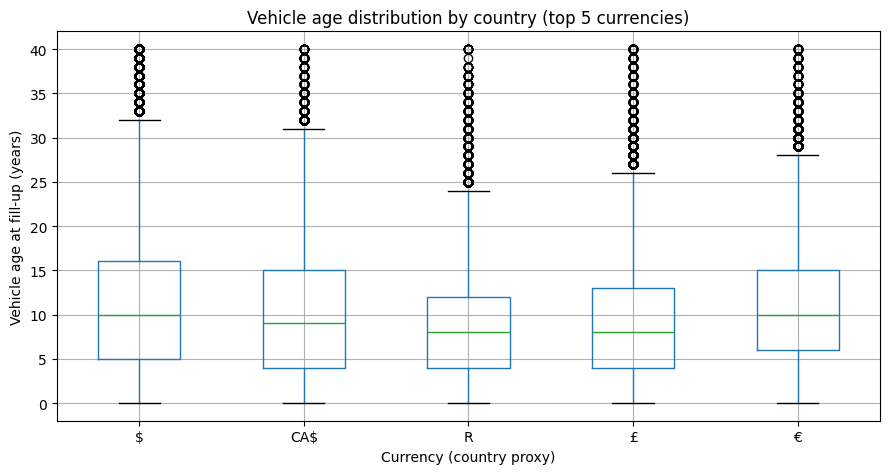

In [21]:
df['fuel_year']   = df['date_fueled_dt'].dt.year
df['vehicle_age'] = df['fuel_year'] - df['vehicle_year']

print(f"Rows with a valid vehicle age: {df['vehicle_age'].notna().sum():,} "
      f"({df['vehicle_age'].notna().mean()*100:.2f}%)")
print(f"Median vehicle age (all rows): {df['vehicle_age'].median():.0f} years")
print(f"Negative ages (fuelled before the stated model year): {(df['vehicle_age'] < 0).sum():,} "
      f"({(df['vehicle_age'] < 0).mean()*100:.3f}%)")

top5_currencies = user_currency.value_counts().head(5).index
sub = df[df['currency'].isin(top5_currencies) & df['vehicle_age'].between(0, 40)]

fig, ax = plt.subplots(figsize=(9, 5))
sub.boxplot(column='vehicle_age', by='currency', ax=ax)
plt.suptitle('')
ax.set_title('Vehicle age distribution by country (top 5 currencies)')
ax.set_xlabel('Currency (country proxy)')
ax.set_ylabel('Vehicle age at fill-up (years)')
plt.tight_layout()
plt.show()

**Discussion:** A valid age is available for 1,169,771 rows (99.57%). The overall median vehicle age is 10 years, which is a believable figure for a general vehicle fleet. A small number of rows (2,152, 0.18%) show a *negative* age; the great majority of these (1,852) are only 1–2 years negative, which is easily explained by the car industry's practice of releasing a vehicle with next year's model year in the second half of the current year (e.g. a \"2022\" model on sale from mid-2021) - genuinely plausible. A smaller residual (300 rows, more negative than -2) is more likely a data-entry error. Since outlier trimming is deliberately deferred to Section 4, we do not remove these here, but simply clip the *plot* at 0–40 years for readability. Within that range, median vehicle age is broadly similar across the top five currencies (8–10 years), with South African (`R`) and British (`£`) users skewing slightly younger (median 8 years) than US (`$`), Canadian (`CA$`) and Eurozone (`€`) users (median 9–10 years).

### Q3.4 - Most popular vehicle makes and models [2]

Top 10 makes by number of log entries:
make
ford             139584
toyota           136230
bmw              105505
nissan            86574
volkswagen        74257
honda             65449
mercedes-benz     62486
audi              56944
hyundai           50812
mazda             46434
Name: count, dtype: int64

Top 10 makes by number of unique users:
make
ford             14457
toyota           13500
bmw              11100
nissan            8879
volkswagen        7701
mercedes-benz     6667
honda             6195
audi              5781
hyundai           5001
mazda             4683
Name: user_id, dtype: int64

Top 10 make+model combinations by number of log entries:
make_model
honda civic            8101
toyota 4runner         7811
toyota corolla         7742
ford f-150             7667
honda accord           7645
ford mustang           7534
ford ranger            7426
toyota land_cruiser    7391
toyota camry           7316
jeep wrangler          7061
Name: count, dtype: int64


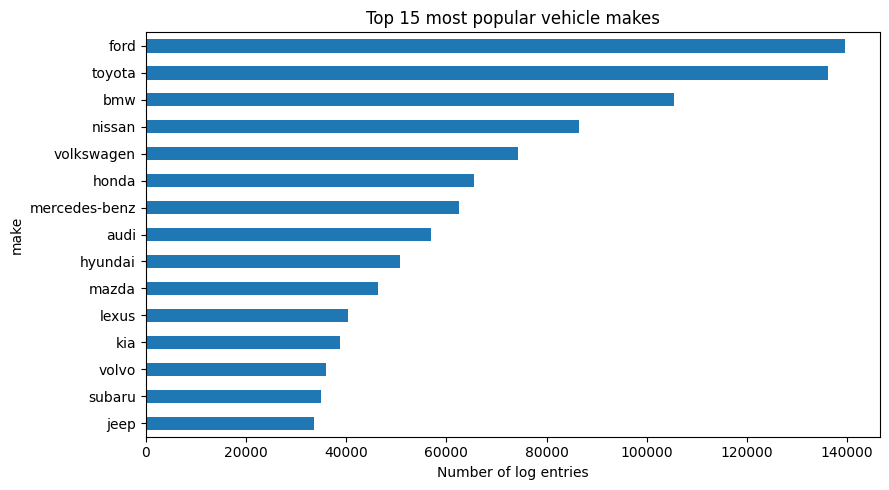

In [23]:
print("Top 10 makes by number of log entries:")
print(df['make'].value_counts().head(10))

print("\nTop 10 makes by number of unique users:")
print(df.groupby('make')['user_id'].nunique().sort_values(ascending=False).head(10))

df['make_model'] = df['make'].astype(str) + ' ' + df['model'].astype(str)
print("\nTop 10 make+model combinations by number of log entries:")
print(df['make_model'].value_counts().head(10))

fig, ax = plt.subplots(figsize=(9, 5))
df['make'].value_counts().head(15).sort_values().plot(kind='barh', ax=ax)
ax.set_xlabel('Number of log entries')
ax.set_title('Top 15 most popular vehicle makes')
plt.tight_layout()
plt.show()

**Discussion:** Ford is the most-logged make overall (139,584 entries from 14,457 unique users), narrowly ahead of Toyota (136,230 entries, 13,500 users); BMW, Nissan and Volkswagen round out the top five by both measures, so the entry-count ranking isn't simply being driven by a handful of unusually active users of one particular make. At the model level, the Honda Civic is the single most-logged model (8,101 entries), but the Ford Mustang has the broadest ownership base of any individual model (819 unique users) - suggesting Civic owners on this platform log slightly more fill-ups per person, on average, than Mustang owners do.